# 
**Bridge Condition Prediction System**

**Sprint 2: Model Building & Evaluation**

This is a binary classification problem (1 = Good, 0 = Poor), so the classification models and metrics are used.

## Data Preparation (from Sprint 1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/bridge_data_clean.csv")

# One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=["material_type", "maintenance_level"], drop_first=True, dtype=int)

# Train-Test Split (80/20, stratified)
X = df_encoded.drop("bridge_condition", axis=1)
y = df_encoded["bridge_condition"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Scaling (fit on training data only)
numerical_features = ["age_of_bridge", "traffic_volume"]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)
print("\nGood bridges in test set:", y_test.sum(), "of", len(y_test))

Training Data Shape: (473, 5)
Testing Data Shape: (119, 5)

Good bridges in test set: 20 of 119


The same preprocessing as Sprint 1 is repeated here (same split and `random_state=42`) so the notebook runs on its own from `bridge_data_clean.csv`. The test set has only **20 good bridges out of 119**, so results will be noisy.

## Step 1: Baseline Model (Logistic Regression)

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_base = log_reg.predict(X_test_scaled)

print("Baseline - Logistic Regression")
print("Accuracy :", round(accuracy_score(y_test, y_pred_base), 3))
print("Precision:", round(precision_score(y_test, y_pred_base), 3))
print("Recall   :", round(recall_score(y_test, y_pred_base), 3))
print("F1 Score :", round(f1_score(y_test, y_pred_base), 3))

print("\nAccuracy of always predicting 'Poor':", round(1 - y_test.mean(), 3))

Baseline - Logistic Regression
Accuracy : 0.832
Precision: 0.5
Recall   : 0.35
F1 Score : 0.412

Accuracy of always predicting 'Poor': 0.832


The baseline reaches 83.2% accuracy, which is **exactly the same as always predicting "Poor"** (83.2%). Its recall is only 0.35, so it finds just 7 of the 20 good bridges. Because of the class imbalance, **accuracy alone is misleading, and F1 (for the Good class) is used as the main metric** from here on.

## Step 2: Train Multiple Models

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": log_reg,
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(random_state=42),
    "Naive Bayes": GaussianNB(),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
SVM trained
Naive Bayes trained


All five required classification models are trained on the same scaled training data with default settings, so the comparison is fair. No tuning is done in this sprint.

## Step 3: Model Evaluation

In [4]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
print("Test Set Metrics:")
print(results_df)

Test Set Metrics:
                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression     0.832      0.500    0.35     0.412
Decision Tree           0.840      0.522    0.60     0.558
Random Forest           0.891      0.667    0.70     0.683
SVM                     0.857      0.615    0.40     0.485
Naive Bayes             0.857      0.600    0.45     0.514


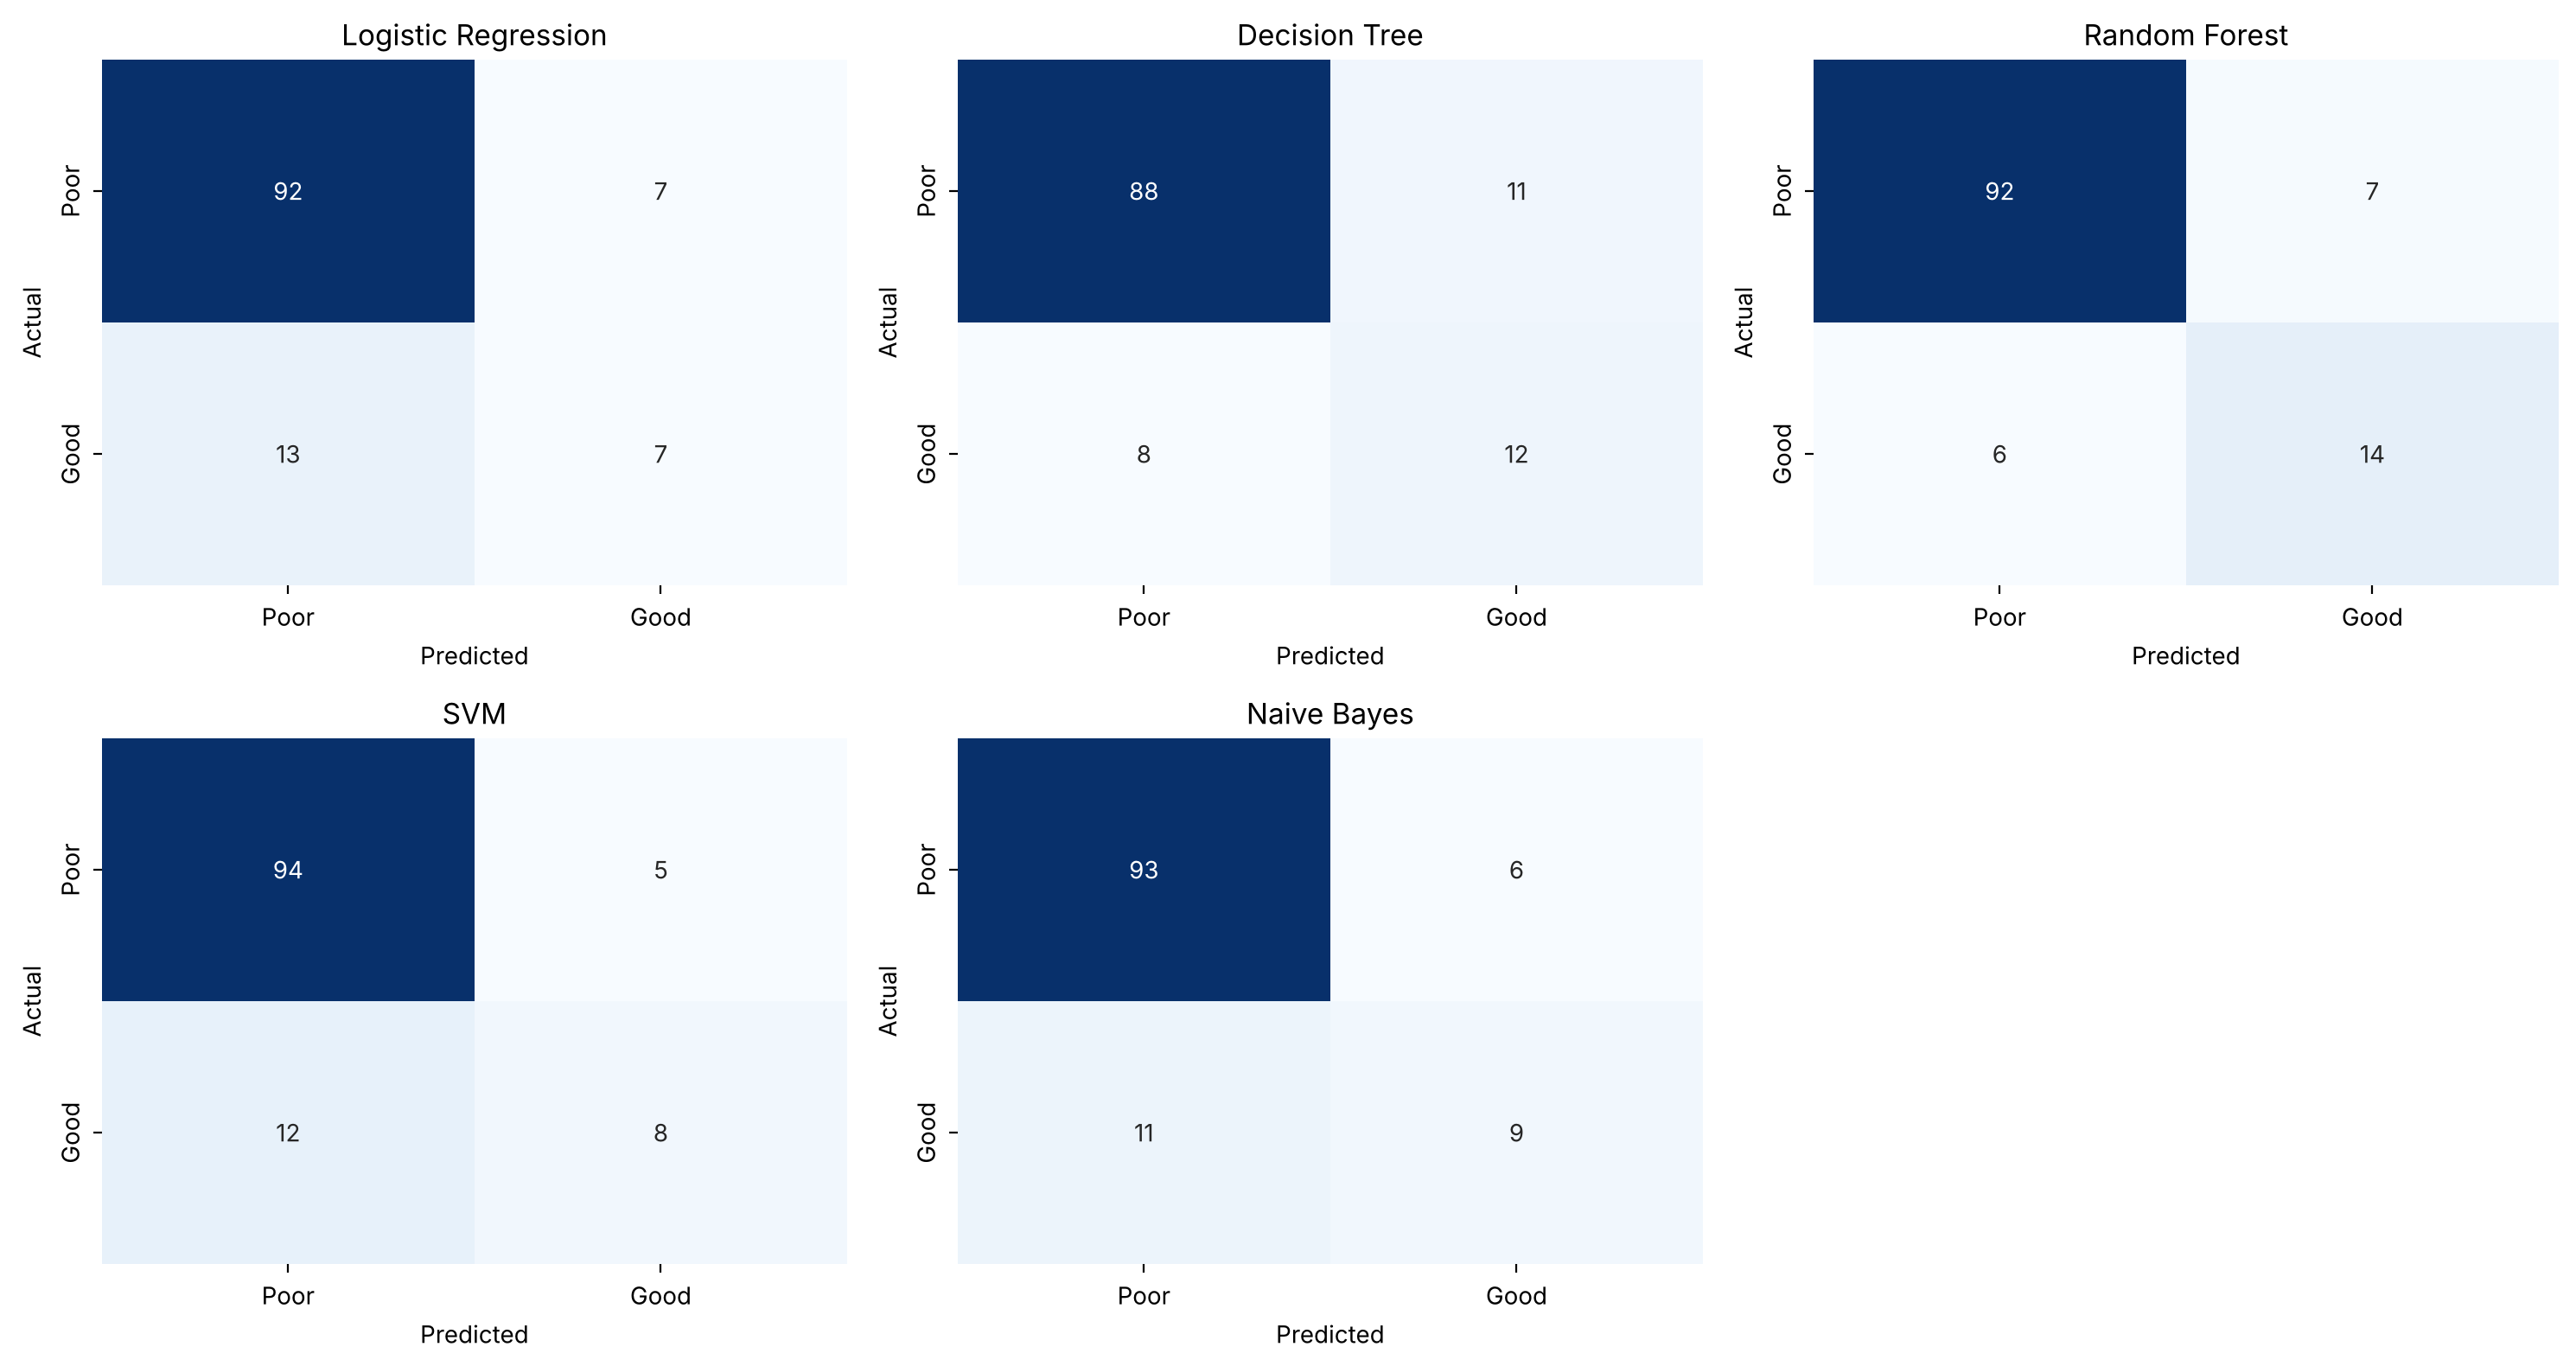

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_scaled))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Poor", "Good"], yticklabels=["Poor", "Good"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

- **Random Forest** scores highest on the test set: accuracy 0.891, precision 0.667, recall 0.700, F1 0.683.
- **Decision Tree** is next (F1 0.558), followed by Naive Bayes (0.514), SVM (0.485) and the Logistic Regression baseline (0.412).
- **SVM, Naive Bayes and Logistic Regression have low recall (0.35 to 0.45).** They miss more than half of the good bridges, even though their accuracy looks fine (0.83 to 0.86).
- Every model beats the 83.2% "always Poor" accuracy except the baseline, which only ties it.

## Step 4: Overfitting & Underfitting Check

In [6]:
fit_rows = []

for name, model in models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    fit_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train F1": f1_score(y_train, train_pred),
        "Test F1": f1_score(y_test, test_pred),
    })

fit_df = pd.DataFrame(fit_rows).set_index("Model")
fit_df["F1 Gap"] = fit_df["Train F1"] - fit_df["Test F1"]
fit_df["Overfitting?"] = np.where(fit_df["F1 Gap"] > 0.15, "Yes", "No")
print(fit_df.round(3))

                     Train Accuracy  Test Accuracy  Train F1  Test F1  F1 Gap  \
Model                                                                           
Logistic Regression           0.846          0.832     0.459    0.412   0.047   
Decision Tree                 1.000          0.840     1.000    0.558   0.442   
Random Forest                 1.000          0.891     1.000    0.683   0.317   
SVM                           0.875          0.857     0.576    0.485   0.091   
Naive Bayes                   0.865          0.857     0.562    0.514   0.047   

                    Overfitting?  
Model                             
Logistic Regression           No  
Decision Tree                Yes  
Random Forest                Yes  
SVM                           No  
Naive Bayes                   No  


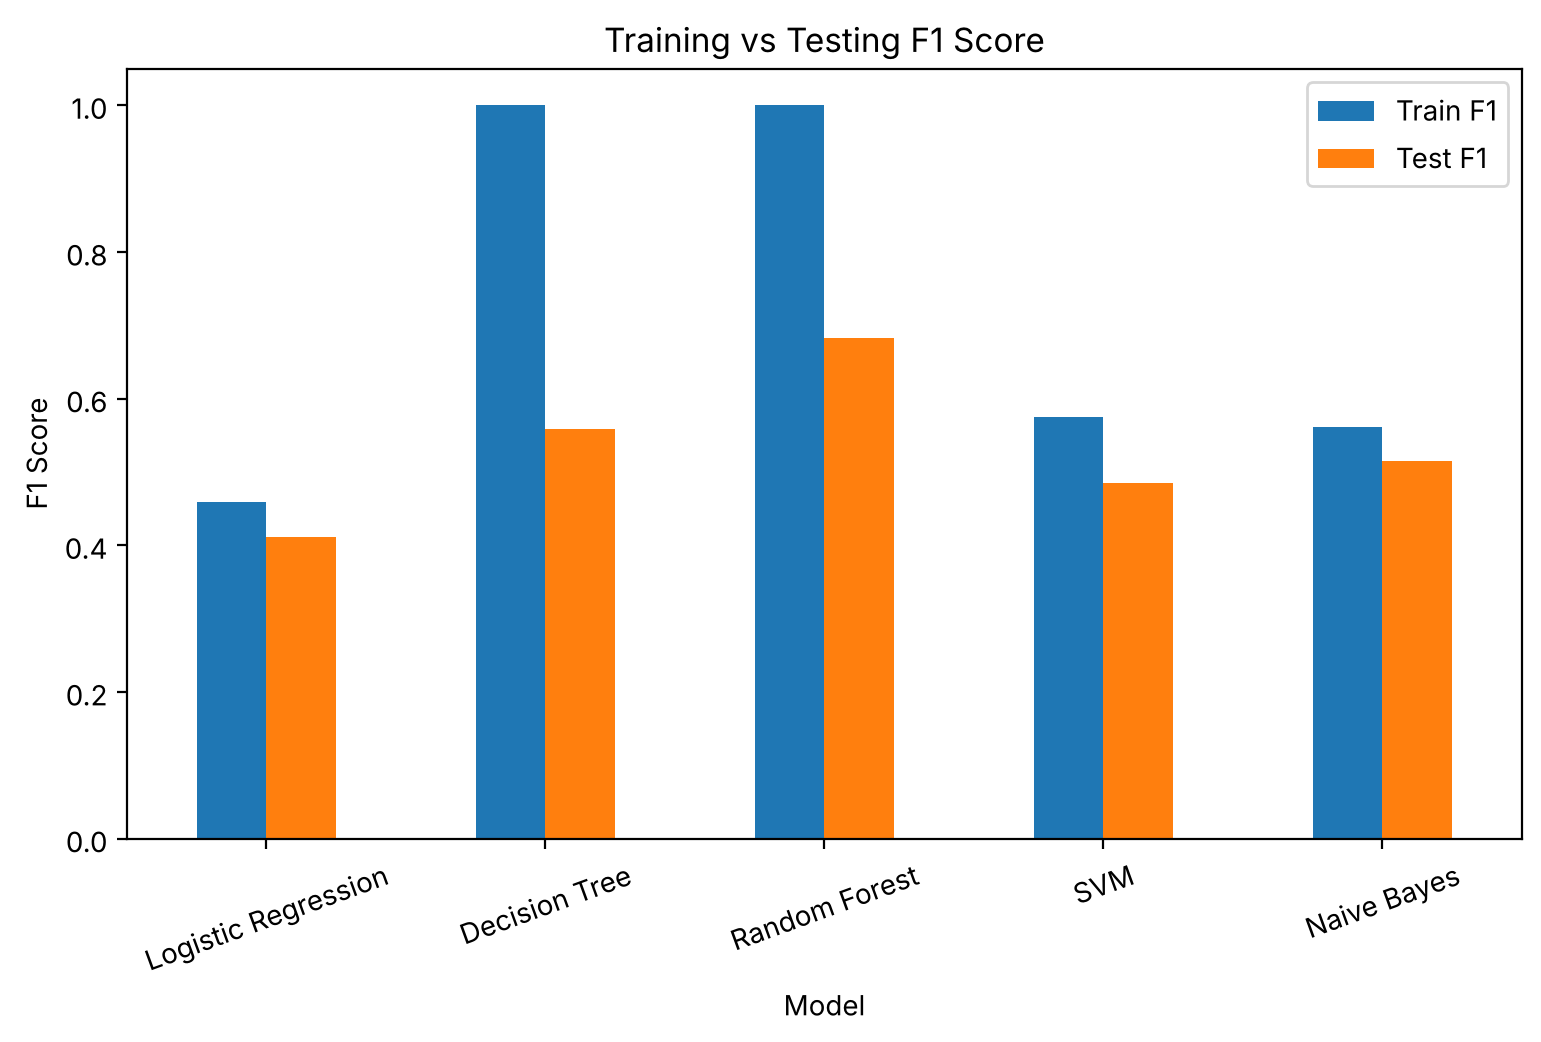

In [7]:
fit_df[["Train F1", "Test F1"]].plot(kind="bar", figsize=(9, 5))
plt.title("Training vs Testing F1 Score")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.show()

A model is marked as **overfitting when its training F1 is more than 0.15 above its test F1**.
- **Decision Tree** (train F1 1.00 vs test 0.56) and **Random Forest** (1.00 vs 0.68) overfit. Both score 100% on the training data, which means they have memorized it.
- **Logistic Regression, SVM and Naive Bayes** have small train-test gaps (0.05 to 0.09), so they do not overfit. However, their training F1 is also low (0.46 to 0.58), so they are **underfitting**: the simple models cannot capture the relationship, which suggests the features are only weakly predictive.

## Step 5: Model Comparison Table

In [8]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# 5-fold cross-validated F1 on the training data (scaling done inside each fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), clone(model))
    cv_f1[name] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()

remarks = {
    "Logistic Regression": "Baseline. Same accuracy as always predicting Poor; misses most good bridges",
    "Decision Tree": "Memorizes training data (100%); weaker on unseen bridges",
    "Random Forest": "Best test scores, but memorizes training data",
    "SVM": "Low recall (0.40) and lowest CV F1 (0.319); underfits",
    "Naive Bayes": "Stable and no overfitting; best cross-validated F1",
}

comparison = results_df.copy()
comparison["CV F1"] = pd.Series(cv_f1)
comparison["Overfitting?"] = fit_df["Overfitting?"]
comparison["Remarks"] = pd.Series(remarks)

pd.set_option("display.max_colwidth", None)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1 Score,CV F1,Overfitting?,Remarks
Model,,,,,,,
Logistic Regression,0.832,0.500,0.35,0.412,0.434,No,Baseline. Same accuracy as always predicting Poor; misses most good bridges
Decision Tree,0.840,0.522,0.60,0.558,0.547,Yes,Memorizes training data (100%); weaker on unseen bridges
Random Forest,0.891,0.667,0.70,0.683,0.478,Yes,"Best test scores, but memorizes training data"
SVM,0.857,0.615,0.40,0.485,0.319,No,Low recall (0.40) and lowest CV F1 (0.319); underfits
Naive Bayes,0.857,0.600,0.45,0.514,0.549,No,Stable and no overfitting; best cross-validated F1


- By **test-set** scores, Random Forest is clearly first. By **5-fold cross-validated F1**, Naive Bayes (0.549) and Decision Tree (0.547) edge ahead of Random Forest (0.478), and the folds vary by about ±0.08.
- With only 20 good bridges in the test set, the differences between the top models are **within normal noise**, so the ranking should be treated as indicative, not final.

## Final Result: Best Baseline Model

In [9]:
best = results_df["F1 Score"].idxmax()
print("Best model on the test set (highest F1):", best)
print(results_df.loc[best])

Best model on the test set (highest F1): Random Forest
Accuracy     0.891
Precision    0.667
Recall       0.700
F1 Score     0.683
Name: Random Forest, dtype: float64


### Summary
1. Logistic Regression was the baseline (F1 0.412). Its accuracy matched the "always Poor" guess, so accuracy alone is not a useful measure here.
2. Five classification models were trained and evaluated with accuracy, precision, recall, F1 and confusion matrices.
3. Decision Tree and Random Forest overfit. Logistic Regression, SVM and Naive Bayes underfit.
4. **Best baseline model: Random Forest** (accuracy 0.891, F1 0.683 on the test set). It overfits, and cross-validation shows the margin over Naive Bayes and Decision Tree is small.

**Notes for Sprint 3:** reduce overfitting in Random Forest and Decision Tree (limit `max_depth`, increase `min_samples_leaf`), try `class_weight="balanced"` to raise recall on good bridges, and tune hyperparameters with cross-validation. Confirm with the data owner that 1 = Good, since older and busier bridges being "good" is unusual.